# Лабораторная 2. Классическая обработка изображений

Задание целиком: `labs/lab02/README.md` в репозитории курса.

Ноутбук один на обе части:
- **Часть 1** (после лекции 2): освещённость и шум по всем фото, гистограммы, коррекция яркости, сравнение фильтров;
- **Часть 2** (после лекции 3): выделение животного на фото, проверка маски по разметке, признаки формы.

Как работать:
1. В первой ячейке впишите свой номер варианта.
2. Заполняйте ячейки с пометкой `TODO` сверху вниз. Ячейки без `TODO` уже готовы, их менять не нужно.
3. Пока вы не дошли до части 2, её ячейки можно не трогать: Run All проходит через них без ошибок.
4. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

В Kaggle включите интернет: Settings → Internet → On.

## 0. Установка и загрузка данных

Ячейка определяет, где запущен ноутбук, находит или скачивает `get_data.py` из репозитория курса и загружает ваш вариант. Ничего в ней менять не нужно, кроме `VARIANT`.

In [4]:
VARIANT = 1   # TODO: ваш порядковый номер в списке группы, например 7
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import os
import sys
import inspect
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab02/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: colab | папка данных: /content/data
Вариант 01 уже на месте: /content/data/variant_01
данные варианта: /content/data/variant_01
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [5]:
import time

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from skimage.restoration import estimate_sigma
from skimage.metrics import structural_similarity

IMG_DIR = DATA_DIR / "images"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

labels = pd.read_csv(DATA_DIR / "labels.csv")
print(len(labels), "фото,", labels["breed"].nunique(), "породы:", ", ".join(labels["breed"].unique()))
print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

795 фото, 4 породы: Bengal, Egyptian_Mau, great_pyrenees, havanese
OpenCV 5.0.0 | numpy 2.4.6 | pandas 2.2.3


### Общие функции

Готовый код, менять не нужно.

- `load_rgb(filename)` читает фото через Pillow с `.convert("RGB")` (в датасете есть файлы в режимах `L`, `RGBA`, `P`, это вы видели в лабе 1) и уменьшает его так, чтобы длинная сторона стала 512 px. Одинаковый масштаб нужен, чтобы ядро 5×5 действовало на всех фото одинаково.
- `load_trimap(filename, shape)` читает trimap и приводит его к размеру фото через `cv2.INTER_NEAREST`: значения 1, 2, 3 не смешиваются.
- `show_grid(images, titles, ncols, path)` рисует картинки сеткой и, если указан `path`, сохраняет PNG.

In [6]:
MAX_SIDE = 512   # длинная сторона после уменьшения, px


def load_rgb(filename):
    """Фото как RGB uint8, длинная сторона MAX_SIDE."""
    with Image.open(IMG_DIR / filename) as im:
        rgb = np.asarray(im.convert("RGB"))
    h, w = rgb.shape[:2]
    scale = MAX_SIDE / max(h, w)
    size = (round(w * scale), round(h * scale))           # cv2.resize ждёт (ширина, высота)
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    return cv2.resize(rgb, size, interpolation=interp)


def load_trimap(filename, shape):
    """Trimap того же размера, что фото: 1 = животное, 2 = фон, 3 = граница."""
    with Image.open(TRIMAP_DIR / (Path(filename).stem + ".png")) as im:
        tri = np.asarray(im)
    return cv2.resize(tri, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)


def show_grid(images, titles=None, ncols=4, path=None, size=3.0):
    """Картинки сеткой: RGB как есть, 2D-массивы в оттенках серого. path: куда сохранить PNG."""
    nrows = (len(images) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for i, img in enumerate(images):
        ax = axes.ravel()[i]
        img = np.asarray(img)
        if img.dtype == bool:
            img = img.astype(np.uint8)
        if img.ndim == 2:
            ax.imshow(img, cmap="gray", vmin=0, vmax=1 if img.max() <= 1 else 255)
        else:
            ax.imshow(img)
        if titles is not None:
            ax.set_title(titles[i], fontsize=9)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=100)
    plt.show()


example = load_rgb(labels["filename"].iloc[0])
print(labels["filename"].iloc[0], example.shape, example.dtype)

Bengal_1.jpg (512, 341, 3) uint8


# Часть 1. Освещённость, шум, фильтры

Делается после лекции 2. Результат части: четыре числа по каждому фото, гистограммы, сравнение способов поправить тёмные фото и сравнение фильтров на зашумлённых фото. Из этой части дальше понадобится одна переменная `BEST_FILTER`.

## 1.1 Четыре числа по каждому фото

| Число | Что показывает | Как считать |
|---|---|---|
| `mean_L` | средняя яркость | среднее канала L из `cv2.COLOR_RGB2LAB` (в 8-битном OpenCV L идёт от 0 до 255) |
| `std_L` | контраст | стандартное отклонение того же канала |
| `noise_sigma` | оценка шума в единицах яркости | `estimate_sigma(gray)` из `skimage.restoration` |
| `sharpness` | резкость: у размытого кадра мало перепадов | дисперсия `cv2.Laplacian(gray, cv2.CV_64F)` |

Допишите функцию `image_stats`. Следующая ячейка готова: она пройдёт по всем фото и сохранит `results/part1_stats.csv`.

In [9]:
def image_stats(rgb):
    """Словарь {"mean_L", "std_L", "noise_sigma", "sharpness"} для одного кадра."""
    L = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[:, :, 0]
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

    return {
        "mean_l": float(L.mean()),
        "std_l": float(L.std()),
        "noise_sigma": float(estimate_sigma(gray)),
        "sharpness": float(cv2.Laplacian(gray, cv2.CV_64F).var())
    }
    # TODO: L = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[..., 0]
    # TODO: gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    # TODO: верните четыре числа как float, например "mean_L": float(L.mean())


In [10]:
rows = []
for r in labels.itertuples():
    with Image.open(IMG_DIR / r.filename) as im:
        width, height = im.size                      # исходный размер файла
    rows.append({"filename": r.filename, "breed": r.breed, "species": r.species,
                 "width": width, "height": height, **image_stats(load_rgb(r.filename))})
stats = pd.DataFrame(rows)
stats.to_csv(RESULTS / "part1_stats.csv", index=False, float_format="%.4f")
stats.describe().round(2)

,width,height,mean_l,std_l,noise_sigma,sharpness
count,795.00,795.00,795.00,795.00,795.00,795.00
mean,447.86,388.54,121.29,56.50,1.51,644.91
std,184.78,179.96,32.11,12.85,1.47,917.63
min,150.00,112.00,31.84,24.24,0.00,9.19
25%,345.50,333.00,100.59,47.43,0.60,155.22
50%,500.00,375.00,120.70,56.51,1.06,370.91
75%,500.00,475.00,139.63,65.76,1.93,764.20
max,3264.00,2606.00,235.18,93.65,13.89,10393.25


In [11]:
stats.groupby("breed")[["mean_l", "std_l", "noise_sigma", "sharpness"]].mean().round(2)
# TODO: средние четырёх чисел по породам: stats.groupby("breed")[[...]].mean().round(2)
#       Какая порода темнее остальных? У какой ниже резкость?

,mean_l,std_l,noise_sigma,sharpness
breed,,,,
Bengal,124.47,58.36,1.36,596.68
Egyptian_Mau,118.51,52.90,0.87,328.99
great_pyrenees,118.33,56.62,1.74,711.81
havanese,123.79,58.01,2.05,934.27


## 1.2 Гистограммы

Нужен один рисунок `results/histograms.png`: распределение `mean_L` по всем фото и гистограммы каналов R, G, B самого тёмного и самого светлого фото. Рядом с гистограммами удобно показать сами фото.

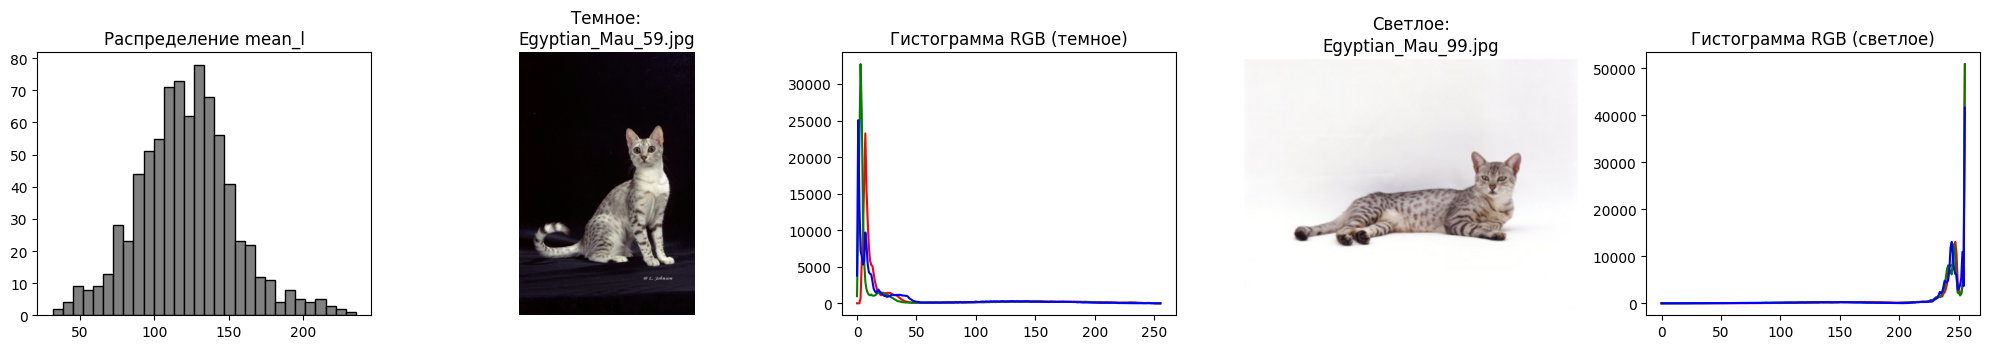

In [12]:
dark_idx = stats["mean_l"].idxmin()
bright_idx = stats["mean_l"].idxmax()

dark_fn = stats.loc[dark_idx, "filename"]
bright_fn = stats.loc[bright_idx, "filename"]

dark_img = load_rgb(dark_fn)
bright_img = load_rgb(bright_fn)

fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))

# 1. Распределение mean_l по всем фото
axes[0].hist(stats["mean_l"], bins=30, color="gray", edgecolor="black")
axes[0].set_title("Распределение mean_l")

# 2. Самое темное фото
axes[1].imshow(dark_img)
axes[1].set_title(f"Темное:\n{dark_fn}")
axes[1].axis("off")

# 3. Гистограмма каналов R, G, B для темного фото (через np.bincount из подсказки)
for i, color in enumerate(["red", "green", "blue"]):
    hist_c = np.bincount(dark_img[..., i].ravel(), minlength=256)
    axes[2].plot(hist_c, color=color)
axes[2].set_title("Гистограмма RGB (темное)")

# 4. Самое светлое фото
axes[3].imshow(bright_img)
axes[3].set_title(f"Светлое:\n{bright_fn}")
axes[3].axis("off")

# 5. Гистограмма каналов R, G, B для светлого фото
for i, color in enumerate(["red", "green", "blue"]):
    hist_c = np.bincount(bright_img[..., i].ravel(), minlength=256)
    axes[4].plot(hist_c, color=color)
axes[4].set_title("Гистограмма RGB (светлое)")

plt.tight_layout()
plt.savefig(RESULTS / "histograms.png", dpi=100)
plt.show()
# TODO: самое тёмное и самое светлое фото: stats.loc[stats["mean_L"].idxmin(), "filename"] и idxmax()
# TODO: plt.subplots(1, 5, figsize=(20, 3.6)):
#       гистограмма stats["mean_L"] (bins=30), затем для каждого из двух фото само фото и гистограммы каналов.
#       Гистограмма канала c: np.bincount(rgb[..., c].ravel(), minlength=256) или cv2.calcHist
# TODO: plt.savefig(RESULTS / "histograms.png", dpi=100)

## 1.3 Освещённость

Возьмите 5 самых тёмных фото и сравните четыре способа их поправить:

| Метод | Что делает |
|---|---|
| `eq_rgb` | `cv2.equalizeHist` по каждому каналу R, G, B отдельно |
| `eq_L` | `cv2.equalizeHist` только по каналу L в Lab, каналы a и b не трогаем |
| `clahe_L` | CLAHE по каналу L: `cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))` |
| `gamma` | гамма-коррекция `255 * (x / 255) ** γ`; при γ < 1 тёмные места светлеют сильнее светлых |

Для каждого фото и метода нужны `mean_L` и `std_L` после коррекции и сдвиг цвета: насколько изменились каналы a и b в Lab. Функция `color_shift` готова.

In [16]:
def color_shift(before, after):
    """Средний сдвиг цвета |Δa| + |Δb| в Lab между двумя RGB-кадрами. 0 = оттенки не изменились."""
    lab0 = cv2.cvtColor(before, cv2.COLOR_RGB2LAB).astype(np.float32)
    lab1 = cv2.cvtColor(after, cv2.COLOR_RGB2LAB).astype(np.float32)
    return float(np.abs(lab1[..., 1:] - lab0[..., 1:]).sum(axis=2).mean())

In [17]:
GAMMA = 0.5   # можно подобрать своё значение


def correct(rgb, method):
    if method == "eq_rgb":
        r, g, b = cv2.split(rgb)
        r_eq = cv2.equalizeHist(r)
        g_eq = cv2.equalizeHist(g)
        b_eq = cv2.equalizeHist(b)
        return cv2.merge([r_eq, g_eq, b_eq])

    elif method == "eq_l":
        lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        l_eq = cv2.equalizeHist(l)
        lab_eq = cv2.merge([l_eq, a, b])
        return cv2.cvtColor(lab_eq, cv2.COLOR_LAB2RGB)

    elif method == "clahe_l":
        lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        l_clahe = clahe.apply(l)
        lab_clahe = cv2.merge([l_clahe, a, b])
        return cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2RGB)

    elif method == "gamma":
        i = np.arange(256, dtype=np.float32)
        lut = np.clip(255 * (i / 255) ** GAMMA, 0, 255).astype(np.uint8)
        return cv2.LUT(rgb, lut)

    return rgb
    """method: "eq_rgb", "eq_L", "clahe_L" или "gamma". Возвращает RGB uint8 того же размера."""
    # TODO: eq_rgb: cv2.split(rgb), equalizeHist для каждого канала, cv2.merge
    # TODO: eq_L и clahe_L: L, a, b = cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)),
    #       обработать только L, собрать cv2.merge([L, a, b]) и вернуть через cv2.COLOR_LAB2RGB
    # TODO: gamma: таблица lut из 256 значений 255 * (i / 255) ** GAMMA в uint8, затем cv2.LUT(rgb, lut)


,mean_l,std_l,color_shift
method,,,
clahe_L,39.64,55.87,0.00
eq_L,39.64,55.87,0.00
eq_rgb,146.26,62.26,16.71
gamma,85.23,56.83,6.34
original,39.64,55.87,0.00


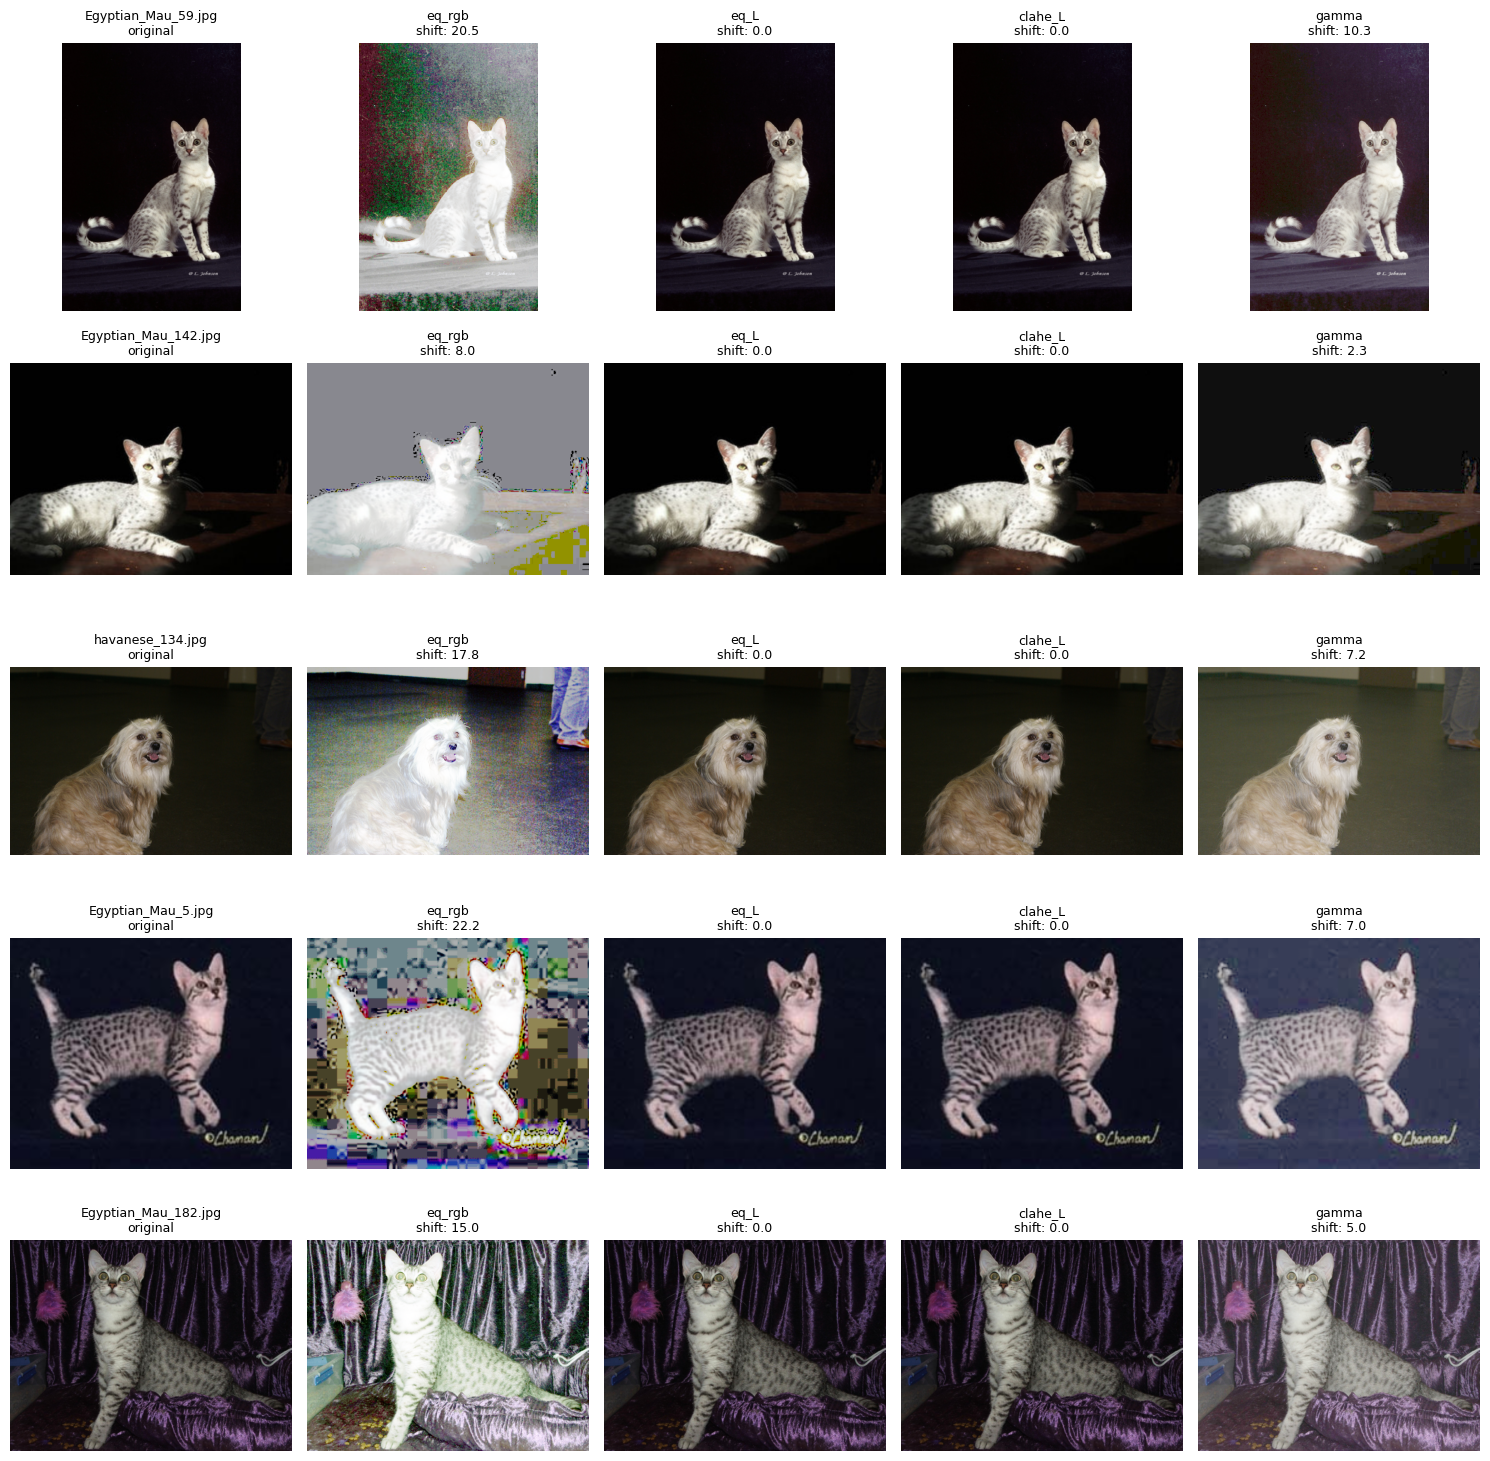

In [18]:
METHODS = ["eq_rgb", "eq_L", "clahe_L", "gamma"]

# 1. Берем 5 самых темных фото
dark_5 = stats.nsmallest(5, "mean_l")

rows = []
grid_images = []
grid_titles = []

for r in dark_5.itertuples():
    fn = r.filename
    img_orig = load_rgb(fn)

    # Исходное фото (точка отсчета для метода "original")
    L_orig = cv2.cvtColor(img_orig, cv2.COLOR_RGB2LAB)[:, :, 0]
    rows.append({
        "filename": fn,
        "method": "original",
        "mean_l": float(L_orig.mean()),
        "std_l": float(L_orig.std()),
        "color_shift": 0.0
    })
    grid_images.append(img_orig)
    grid_titles.append(f"{fn}\noriginal")

    # Прогоняем по каждому методу из METHODS
    for m in METHODS:
        img_corr = correct(img_orig, m)
        L_corr = cv2.cvtColor(img_corr, cv2.COLOR_RGB2LAB)[:, :, 0]
        shift = color_shift(img_orig, img_corr)

        rows.append({
            "filename": fn,
            "method": m,
            "mean_l": float(L_corr.mean()),
            "std_l": float(L_corr.std()),
            "color_shift": float(shift)
        })
        grid_images.append(img_corr)
        grid_titles.append(f"{m}\nshift: {shift:.1f}")

illum = pd.DataFrame(rows)

# Выводим средние по методам
display(illum.groupby("method")[["mean_l", "std_l", "color_shift"]].mean().round(2))

# Сохраняем сетку 5 x 5 (5 строк на каждое фото, 5 колонок: оригинал + 4 метода)
show_grid(grid_images, grid_titles, ncols=5, path=RESULTS / "illumination.png")

# TODO: 5 самых тёмных фото: stats.nsmallest(5, "mean_L")
# TODO: таблица illum, строка на пару (фото, метод): filename, method, mean_L, std_L, color_shift.
#       Строки method="original" для исходных фото дают точку отсчёта.
#       Выведите средние по методам: illum.groupby("method")[["mean_L", "std_L", "color_shift"]].mean()
# TODO: сетка 5 × 5 (исходное и 4 метода в строке): show_grid(..., ncols=5, path=RESULTS / "illumination.png")

## 1.4 Свёртка руками

`cv2.blur(img, (3, 3))` усредняет каждый пиксель с восемью соседями. То же самое делает свёртка `cv2.filter2D` с ядром 3×3, в котором все девять чисел равны 1/9. Проверьте это на любом фото.

In [19]:
# Загрузим любую тестовую картинку из датасета
test_img = load_rgb(labels["filename"].iloc[0])

# Создаем ядро 3x3, где каждое число равно 1/9
kernel = np.ones((3, 3), np.float32) / 9

# Применяем фильтрацию двумя способами
blurred_builtin = cv2.blur(test_img, (3, 3))
blurred_custom = cv2.filter2D(test_img, -1, kernel)

# Считаем максимальную разницу между результатами (переведя в int перед вычитанием)
diff = np.abs(blurred_builtin.astype(np.int32) - blurred_custom.astype(np.int32)).max()

print(f"Максимальная разница между встроенным blur и свёрткой руками: {diff}")
# TODO: kernel = np.ones((3, 3), np.float32) / 9
# TODO: сравните cv2.filter2D(img, -1, kernel) и cv2.blur(img, (3, 3)); напечатайте максимум модуля разницы
#       (переведите оба результата в int перед вычитанием: в uint8 разность 3 - 5 даёт 254)
# По желанию: ядро резкости [[0, -1, 0], [-1, 5, -1], [0, -1, 0]] и сравнение кропов до и после.

Максимальная разница между встроенным blur и свёрткой руками: 0


## 1.5 Шум и фильтры

У каждого варианта свой шум, он задан в `NOISE_PLAN`:

- `gauss`: к каждому пикселю добавлено случайное число из нормального распределения со стандартным отклонением `sigma` (в единицах яркости 0..255);
- `sp` («соль и перец»): доля `amount` пикселей стала чисто чёрной или чисто белой;
- `mix`: оба шума сразу.

Шум добавляется к 30 случайным фото варианта. Фильтр получает зашумлённое фото, результат сравнивается с исходным:

- PSNR в децибелах (`cv2.PSNR`): чем больше, тем ближе к исходному;
- SSIM от 0 до 1 (`structural_similarity`): похожесть по локальной структуре, ближе к тому, что видит глаз;
- время на кадр в миллисекундах.

Сравните `cv2.blur`, `cv2.GaussianBlur`, `cv2.medianBlur` с ядрами 3, 5, 7 и `cv2.bilateralFilter`. По желанию добавьте `cv2.fastNlMeansDenoisingColored`.

In [20]:
NOISE_PLAN = {
    0: {"kind": "gauss", "sigma": 20},
    1: {"kind": "sp", "amount": 0.05},
    2: {"kind": "mix", "sigma": 15, "amount": 0.03},
    3: {"kind": "gauss", "sigma": 30},
    4: {"kind": "sp", "amount": 0.10},
    5: {"kind": "mix", "sigma": 20, "amount": 0.05},
    6: {"kind": "gauss", "sigma": 10},
    7: {"kind": "sp", "amount": 0.02},
    8: {"kind": "mix", "sigma": 10, "amount": 0.02},
    9: {"kind": "gauss", "sigma": 25},
    10: {"kind": "sp", "amount": 0.08},
    11: {"kind": "mix", "sigma": 15, "amount": 0.05},
    12: {"kind": "gauss", "sigma": 15},
    13: {"kind": "sp", "amount": 0.04},
    14: {"kind": "mix", "sigma": 20, "amount": 0.03},
    15: {"kind": "gauss", "sigma": 30},
    16: {"kind": "sp", "amount": 0.06},
    17: {"kind": "mix", "sigma": 10, "amount": 0.04},
    18: {"kind": "gauss", "sigma": 20},
    19: {"kind": "sp", "amount": 0.03},
    20: {"kind": "mix", "sigma": 25, "amount": 0.05},
    21: {"kind": "gauss", "sigma": 25},
    22: {"kind": "sp", "amount": 0.10},
}


def add_noise(rgb, kind, sigma=0, amount=0.0, seed=0):
    """Зашумлённая копия RGB-кадра. kind: "gauss", "sp" или "mix"."""
    rng = np.random.default_rng(seed)
    out = rgb.astype(np.float32)
    if kind in ("gauss", "mix"):
        out = out + rng.normal(0, sigma, out.shape)
    out = np.clip(out, 0, 255).astype(np.uint8)
    if kind in ("sp", "mix"):
        r = rng.random(out.shape[:2])
        out[r < amount / 2] = 0
        out[r > 1 - amount / 2] = 255
    return out

шум варианта: kind=sp amount=0.05


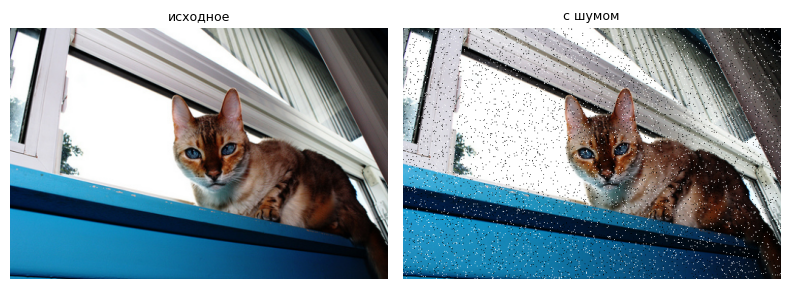

In [21]:
NOISE = NOISE_PLAN[VARIANT]
NOISE_NAME = " ".join(f"{k}={v}" for k, v in NOISE.items())
sample = labels.sample(30, random_state=VARIANT)
clean = [load_rgb(fn) for fn in sample["filename"]]
noisy = [add_noise(img, seed=VARIANT * 100 + i, **NOISE) for i, img in enumerate(clean)]
print("шум варианта:", NOISE_NAME)
show_grid([clean[0], noisy[0]], ["исходное", "с шумом"], ncols=2, size=4)

In [23]:
# TODO: словарь FILTERS: имя фильтра -> функция, которая принимает RGB uint8 и возвращает RGB uint8.
#       Нужны blur, GaussianBlur и medianBlur с ядрами 3, 5, 7 и bilateralFilter, например cv2.bilateralFilter(img, 9, 75, 75).
#       Пример записи: "median3": lambda img: cv2.medianBlur(img, 3)

FILTERS = {
    "blur3": lambda img: cv2.blur(img, (3, 3)),
    "blur5": lambda img: cv2.blur(img, (5, 5)),
    "blur7": lambda img: cv2.blur(img, (7, 7)),
    "gauss3": lambda img: cv2.GaussianBlur(img, (3, 3), 0),
    "gauss5": lambda img: cv2.GaussianBlur(img, (5, 5), 0),
    "gauss7": lambda img: cv2.GaussianBlur(img, (7, 7), 0),
    "median3": lambda img: cv2.medianBlur(img, 3),
    "median5": lambda img: cv2.medianBlur(img, 5),
    "median7": lambda img: cv2.medianBlur(img, 7),
    "bilateral": lambda img: cv2.bilateralFilter(img, 9, 75, 75),
}

In [25]:
def quality(clean_img, out_img):
    """Насколько результат фильтра похож на чистый кадр: {"psnr": ..., "ssim": ...}."""
    # TODO: psnr через cv2.PSNR(clean_img, out_img)
    # TODO: ssim через structural_similarity(clean_img, out_img, channel_axis=2, data_range=255)
    psnr_val = cv2.PSNR(clean_img, out_img)
    ssim_val = structural_similarity(clean_img, out_img, channel_axis=2, data_range=255)
    return {"psnr": float(psnr_val), "ssim": float(ssim_val)}


In [26]:
# Готовый цикл: каждый фильтр на 30 фото, время и качество. "none" = зашумлённое фото без фильтра.
rows = []
for name, f in {"none": lambda img: img, **FILTERS}.items():
    for fn, c, n in zip(sample["filename"], clean, noisy):
        t0 = time.perf_counter()
        out = f(n)
        ms = (time.perf_counter() - t0) * 1000
        rows.append({"filter": name, "filename": fn, "ms": ms, **quality(c, out)})
filt = pd.DataFrame(rows)
filt_summary = filt.groupby("filter").mean(numeric_only=True).round(4)
filt_summary.insert(0, "noise", NOISE_NAME)
filt_summary.to_csv(RESULTS / "filters.csv")
filt_summary

,noise,ms,psnr,ssim
filter,,,,
bilateral,kind=sp amount=0.05,42.4983,17.8943,0.3428
blur3,kind=sp amount=0.05,0.3935,25.7708,0.6183
blur5,kind=sp amount=0.05,0.4609,26.5074,0.6607
blur7,kind=sp amount=0.05,0.7685,25.8062,0.6435
gauss3,kind=sp amount=0.05,0.8216,25.3714,0.6109
gauss5,kind=sp amount=0.05,0.8147,26.6807,0.6676
gauss7,kind=sp amount=0.05,1.0934,27.0388,0.6974
median3,kind=sp amount=0.05,0.3835,34.3444,0.9304
median5,kind=sp amount=0.05,1.7300,30.4388,0.8407


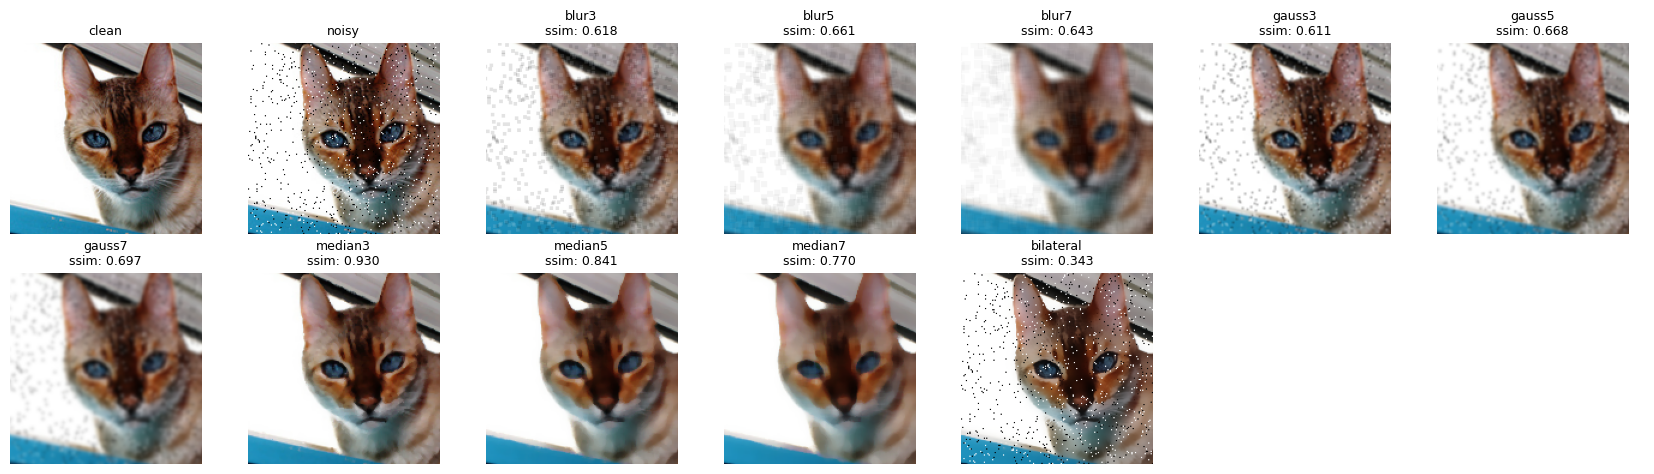

In [28]:
# TODO: кропы 160×160 из центра clean[0]: чистое, с шумом и после каждого фильтра из FILTERS.
#       В подписи удобно вписать SSIM фильтра из filt_summary.
#       show_grid(crops, titles, ncols=7, path=RESULTS / "filters.png", size=2.4)
h, w, _ = clean[0].shape
cy, cx = h // 2, w // 2
half = 80

crops = []
titles = []

# Сбрасываем индекс, чтобы колонка "filter" была доступна
df_res = filt_summary.reset_index()

# Чистое и с шумом
for name, img in [("clean", clean[0]), ("noisy", noisy[0])]:
    crop = img[cy-half:cy+half, cx-half:cx+half]
    crops.append(crop)
    titles.append(name)

# После каждого фильтра
for name in FILTERS.keys():
    filtered_out = FILTERS[name](noisy[0])
    crop = filtered_out[cy-half:cy+half, cx-half:cx+half]

    # Достаем SSIM по колонке "filter"
    row_s = df_res[df_res["filter"] == name]
    ssim_val = row_s["ssim"].values[0] if not row_s.empty else 0.0

    crops.append(crop)
    titles.append(f"{name}\nssim: {ssim_val:.3f}")

show_grid(crops, titles, ncols=7, path=RESULTS / "filters.png", size=2.4)

In [29]:
# TODO: выберите лучший фильтр по таблице filt_summary (метрики, время) и по кропам.
#       Отсортировать таблицу: filt_summary.sort_values("ssim", ascending=False)
BEST_FILTER = "median3"   # TODO: имя из FILTERS, например "median5"

 Фильтр median3 стал абсолютным лидером по ключевым метрикам качества восстановления изображения, достигнув максимальных значений SSIM (0.9304) и PSNR (34.34) среди всех исследованных вариантов. В отличие от линейных фильтров (blur и gauss), которые сглаживают и размывают структуру изображения, медианный фильтр с ядром 3 \times 3 идеально подходит под заданный тип шума «соль и перец». На кропах видно, что он эффективно удаляет случайные черные и белые пиксели, сохраняя при этом резкость границ, мелкую текстуру шерсти и детали объектов, практически не создавая артефактов и обладая высокой скоростью работы (около 0.38 мс на кадр).

# Часть 2 (после лекции 3). Выделение животного и признаки формы

Эту часть делайте после лекции 3. Кто хочет, может сделать её сразу: все функции и подсказки ниже.

Задача: получить маску животного без нейросети. Пайплайн: канал → порог Оцу → полярность → морфология → заливка дыр → самая большая связная компонента → контур и признаки формы. Качество маски проверяем по trimap через IoU, пиксели границы (значение 3) не учитываем.

Из части 1 сюда приходит только `BEST_FILTER`.

In [30]:
def iou_ignore(pred, trimap):
    """IoU маски pred с животным из trimap; пиксели границы (значение 3) не учитываются."""
    valid = trimap != 3
    gt = trimap == 1
    pred = np.asarray(pred) > 0
    inter = np.logical_and(pred, gt)[valid].sum()
    union = np.logical_or(pred, gt)[valid].sum()
    return float(inter / union) if union else float("nan")


def overlay(rgb, mask, color=(0, 255, 0), alpha=0.45):
    """Фото с маской, закрашенной полупрозрачным цветом."""
    out = rgb.copy()
    m = np.asarray(mask) > 0
    out[m] = ((1 - alpha) * out[m] + alpha * np.array(color)).astype(np.uint8)
    return out


# Каналы, из которых можно выбирать. Можно добавить свои.
CHANNELS = {
    "gray": lambda rgb: cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY),
    "S": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))[1],
    "V": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))[2],
    "L": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[0],
    "a": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[1],
    "b": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[2],
}

## 2.1 Один кадр по шагам

Пройдите пайплайн на одном фото и сохраните `results/pipeline.png`: исходное фото, trimap, серое, Оцу, после исправления полярности, после морфологии, после заливки и выбора компоненты, контур на фото, адаптивный порог для сравнения. В подписях укажите IoU масок.

Каждый шаг удобно сразу оформить функцией: в 2.2 из них соберётся `segment`.

In [44]:
EXAMPLE = labels["filename"].sample(1, random_state=VARIANT).iloc[0]   # можно заменить на любое фото варианта
rgb = load_rgb(EXAMPLE)
tri = load_trimap(EXAMPLE, rgb.shape)
print(EXAMPLE, rgb.shape, "значения trimap:", np.unique(tri))

Bengal_9.jpg (341, 512, 3) значения trimap: [1 2 3]


Найденный порог Оцу: 143.0


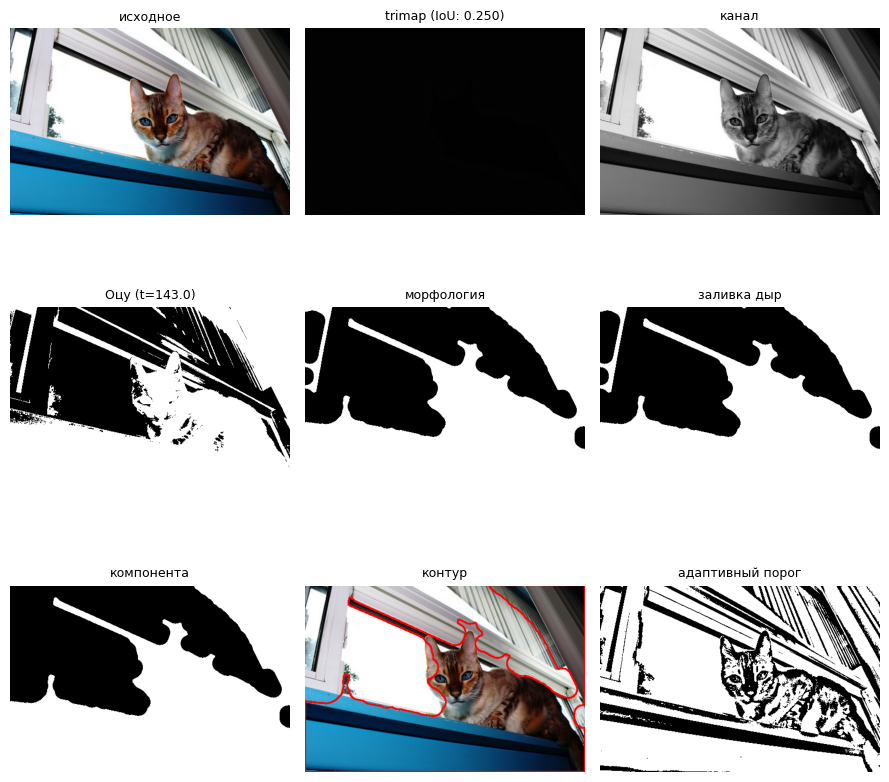

In [46]:
gray = CHANNELS["gray"](rgb)

t, m = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"Найденный порог Оцу: {t}")

# Полярность: инвертируем маску, чтобы кот стал белым (255)
m = cv2.bitwise_not(m)

m_polar = m.copy()

# Морфология (ядра 7 и 31)
kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31))
m_morph = cv2.morphologyEx(m, cv2.MORPH_OPEN, kernel_open)
m_morph = cv2.morphologyEx(m_morph, cv2.MORPH_CLOSE, kernel_close)

# Заливка дыр
flood_img = cv2.copyMakeBorder(m_morph, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)
cv2.floodFill(flood_img, None, (0, 0), 128)
filled_inner = flood_img[1:-1, 1:-1]
m_filled = (filled_inner != 128).astype(np.uint8) * 255

# Самая большая связная компонента
num_labels, labels_cc, stats_cc, centroids = cv2.connectedComponentsWithStats(m_filled, connectivity=8)
if num_labels > 1:
    largest_label = 1 + np.argmax(stats_cc[1:, cv2.CC_STAT_AREA])
    m_comp = (labels_cc == largest_label).astype(np.uint8) * 255
else:
    m_comp = m_filled

# Контур
contours, _ = cv2.findContours(m_comp, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
img_contour = rgb.copy()
cv2.drawContours(img_contour, contours, -1, (255, 0, 0), 2)

# Адаптивный порог
m_adaptive = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 51, 5)

# Сетка из 9 панелей
show_grid(
    [rgb, tri, gray, m_polar, m_morph, m_filled, m_comp, img_contour, m_adaptive],
    ["исходное", f"trimap (IoU: {iou_ignore(m_comp, tri):.3f})", "канал", f"Оцу (t={t:.1f})", "морфология", "заливка дыр", "компонента", "контур", "адаптивный порог"],
    ncols=3,
    path=RESULTS / "pipeline.png"
)

## 2.2 Функция `segment` и выбор канала

`segment` повторяет шаги 2.1 для любого фото. Флаги включают шаги по одному: так в 2.3 будет видно, что даёт каждый. Пока функция не написана, она возвращает пустую маску, и ячейки ниже работают с IoU = 0.

Канал не обязан быть серым: животное может отличаться от фона насыщенностью (`S`) или цветом (`a`, `b`). Сравните минимум два канала из `CHANNELS` готовой функцией `evaluate` и выберите `CHANNEL`. Каждый вызов `evaluate` проходит по всем фото варианта и занимает 10–30 секунд.

In [49]:
def segment(rgb, channel="gray", smooth=True, polarity=True, morph=True, fill=True, k_open=7, k_close=31):
    """Маска животного (bool, размер как у rgb)."""
    # TODO: smooth: если BEST_FILTER задан, rgb = FILTERS[BEST_FILTER](rgb)
    if smooth and BEST_FILTER in FILTERS:
        rgb = FILTERS[BEST_FILTER](rgb)

    # TODO: канал x = CHANNELS[channel](rgb), затем Оцу
    if channel in CHANNELS:
        x = CHANNELS[channel](rgb)
    else:
        x = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

    t, m = cv2.threshold(x, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # TODO: polarity, morph (c k_open и k_close), fill (заливка дыр и самая большая компонента),
    #       каждый шаг только при своём флаге
    if polarity:
        m = cv2.bitwise_not(m)

    if morph:
        k_o = max(1, int(k_open))
        k_c = max(1, int(k_close))
        kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_o, k_o))
        kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_c, k_c))
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, kernel_open)
        m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, kernel_close)

    if fill:
        flood_img = cv2.copyMakeBorder(m, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)
        cv2.floodFill(flood_img, None, (0, 0), 128)
        filled_inner = flood_img[1:-1, 1:-1]
        m_filled = (filled_inner != 128).astype(np.uint8) * 255

        num_labels, labels_cc, stats_cc, centroids = cv2.connectedComponentsWithStats(m_filled, connectivity=8)
        if num_labels > 1:
            largest_label = 1 + np.argmax(stats_cc[1:, cv2.CC_STAT_AREA])
            m = (labels_cc == largest_label).astype(np.uint8) * 255
        else:
            m = m_filled

    # TODO: верните mask > 0
    return m > 0

In [50]:
def evaluate(configs):
    """configs: {имя: параметры segment}. Прогоняет segment на всех фото варианта.
    Возвращает таблицу IoU: строка = фото, столбец = имя набора параметров."""
    rows = []
    for fn in labels["filename"]:
        rgb = load_rgb(fn)
        tri = load_trimap(fn, rgb.shape)
        rows.append({"filename": fn, **{name: iou_ignore(segment(rgb, **kw), tri) for name, kw in configs.items()}})
    return pd.DataFrame(rows).set_index("filename")


def summarize(table):
    """Средняя и медианная IoU по каждому столбцу таблицы из evaluate."""
    return pd.DataFrame({"mean_iou": table.mean(), "median_iou": table.median()}).round(3)

In [52]:
# Сравниваем минимум два канала, например:
ch = evaluate({
    "gray": dict(channel="gray"),
    "S": dict(channel="S")
})
display(summarize(ch))

# Вписываем канал-победитель по результатам таблицы выше
CHANNEL = "S"  # или "S", если он показал лучшие цифры mean_iou

,mean_iou,median_iou
gray,0.332,0.276
S,0.436,0.392


## 2.3 Что даёт каждый шаг

Готовая ячейка: шаги включаются по одному на выбранном канале, результат сохраняется в `results/ablation.csv`.

In [53]:
ABLATION = {
    "1 только Оцу": dict(channel=CHANNEL, smooth=False, polarity=False, morph=False, fill=False),
    "2 + фильтр из части 1": dict(channel=CHANNEL, smooth=True, polarity=False, morph=False, fill=False),
    "3 + полярность": dict(channel=CHANNEL, smooth=True, polarity=True, morph=False, fill=False),
    "4 + морфология": dict(channel=CHANNEL, smooth=True, polarity=True, morph=True, fill=False),
    "5 + заливка и компонента": dict(channel=CHANNEL, smooth=True, polarity=True, morph=True, fill=True),
}
FINAL = ABLATION["5 + заливка и компонента"]

abl = evaluate(ABLATION)
abl_summary = summarize(abl)
abl_summary.to_csv(RESULTS / "ablation.csv", index_label="step")
print("канал:", CHANNEL, "| фильтр:", BEST_FILTER)
abl_summary

канал: S | фильтр: median3


,mean_iou,median_iou
1 только Оцу,0.188,0.063
2 + фильтр из части 1,0.191,0.066
3 + полярность,0.378,0.351
4 + морфология,0.401,0.362
5 + заливка и компонента,0.436,0.392


## 2.4 Признаки формы

Для итоговой маски каждого фото нужны признаки самого большого внешнего контура:

| Признак | Как считать |
|---|---|
| `area_frac` | `cv2.contourArea(c)` / площадь кадра |
| `perimeter` | `cv2.arcLength(c, True)` |
| `x, y, w, h` | `cv2.boundingRect(c)` |
| `elongation` | длинная сторона / короткая сторона `cv2.minAreaRect(c)[1]` |
| `circularity` | 4π × площадь / периметр²; у круга 1, у вытянутой и рваной фигуры меньше |
| `solidity` | площадь / площадь `cv2.convexHull(c)`; лапы и хвост её уменьшают |

Допишите `shape_features`. Следующая ячейка готова: она соберёт `results/masks.csv` (строка на фото: IoU и признаки).

In [54]:
def shape_features(mask):
    """Признаки формы маски: area_frac, perimeter, x, y, w, h, elongation, circularity, solidity."""
    # TODO: contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

    # TODO: если контуров нет, верните {}; иначе возьмите самый большой: max(contours, key=cv2.contourArea)
    if not contours:
        return {}
    c = max(contours, key=cv2.contourArea)

    # TODO: посчитайте признаки из таблицы выше; следите за делением на ноль
    area = cv2.contourArea(c)
    total_area = mask.shape[0] * mask.shape[1]
    area_frac = area / total_area if total_area > 0 else 0.0

    perimeter = cv2.arcLength(c, True)

    x, y, w, h = cv2.boundingRect(c)

    # elongation: длинная сторона / короткая сторона из cv2.minAreaRect(c)[1]
    rect = cv2.minAreaRect(c)
    box_w, box_h = rect[1]
    if box_w > 0 and box_h > 0:
        elongation = max(box_w, box_h) / min(box_w, box_h)
    else:
        elongation = 1.0

    # circularity: 4pi * площадь / периметр^2
    circularity = (4 * np.pi * area) / (perimeter ** 2) if perimeter > 0 else 0.0

    # solidity: площадь / площадь convexHull(c)
    hull = cv2.convexHull(c)
    hull_area = cv2.contourArea(hull)
    solidity = area / hull_area if hull_area > 0 else 0.0

    return {
        "area_frac": float(area_frac),
        "perimeter": float(perimeter),
        "x": int(x),
        "y": int(y),
        "w": int(w),
        "h": int(h),
        "elongation": float(elongation),
        "circularity": float(circularity),
        "solidity": float(solidity)
    }

In [55]:
rows = []
for r in labels.itertuples():
    rgb = load_rgb(r.filename)
    mask = segment(rgb, **FINAL)
    rows.append({"filename": r.filename, "breed": r.breed, "species": r.species,
                 "iou": iou_ignore(mask, load_trimap(r.filename, rgb.shape)), **shape_features(mask)})
masks = pd.DataFrame(rows)
masks.to_csv(RESULTS / "masks.csv", index=False, float_format="%.4f")
masks.head()

,filename,breed,species,iou,area_frac,perimeter,x,y,w,h,elongation,circularity,solidity
0,Bengal_1.jpg,Bengal,cat,0.244644,0.995120,1702.000000,0,0,341,512,1.502941,0.753686,1.000000
1,Bengal_2.jpg,Bengal,cat,0.270286,0.995731,1882.000000,0,0,512,431,1.188372,0.779579,1.000000
2,Bengal_3.jpg,Bengal,cat,0.450435,0.995682,1864.000000,0,0,512,422,1.213777,0.778074,1.000000
3,Bengal_4.jpg,Bengal,cat,0.554693,0.344755,3254.362814,0,0,512,384,1.334204,0.080425,0.443483
4,Bengal_5.jpg,Bengal,cat,0.240303,0.885789,2204.565577,0,0,512,335,1.529940,0.392834,0.898505


In [56]:
# TODO: сводка по породам: masks.groupby("breed")[["iou", "area_frac", "elongation", "circularity", "solidity"]].mean()
#       На какой породе метод работает хуже всего? Отличаются ли кошки и собаки по форме маски?
masks.groupby("breed")[["iou", "area_frac", "elongation", "circularity", "solidity"]].mean()

,iou,area_frac,elongation,circularity,solidity
breed,,,,,
Bengal,0.229779,0.696062,1.476149,0.390906,0.801666
Egyptian_Mau,0.465530,0.696963,1.393680,0.441144,0.828485
great_pyrenees,0.496787,0.685967,1.403307,0.424721,0.836066
havanese,0.554025,0.621880,1.413070,0.399146,0.812404


## 2.5 Лучшие и худшие маски

Галерея из 6 лучших и 6 худших масок по IoU сохраняется в `results/best_worst.png`. Посмотрите на худшие: что у них общего (фон того же цвета, что животное, тёмный кадр, ошибка в самой разметке)?

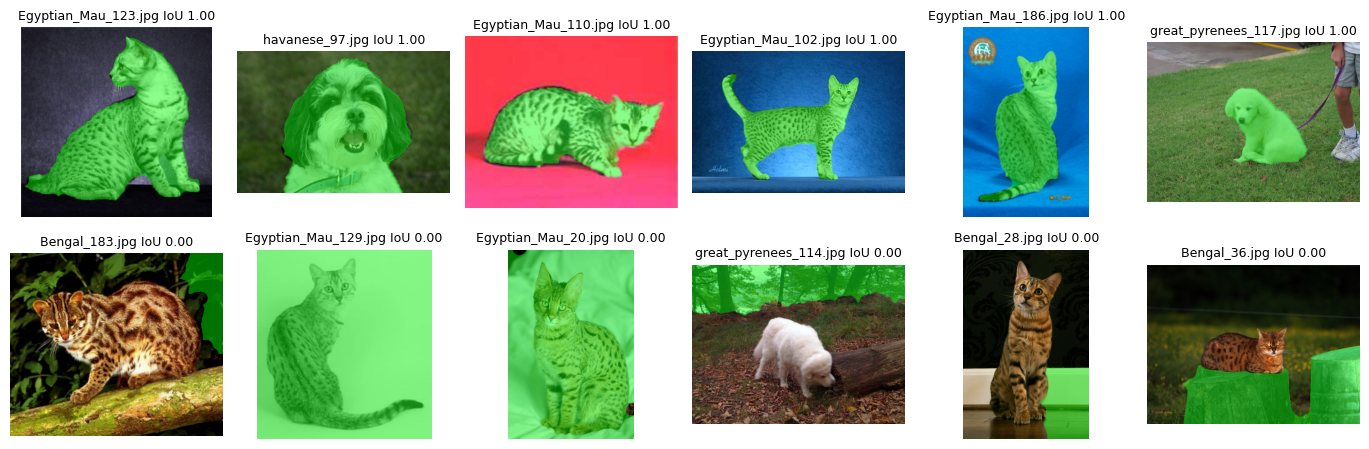

In [57]:
# TODO: ranked = masks.dropna(subset=["iou"]).sort_values("iou", ascending=False)
#       по 6 строк из начала и конца; для каждой: load_rgb, segment(rgb, **FINAL), overlay(rgb, mask)
#       подписи вида "Bengal_12.jpg IoU 0.91"
#       show_grid(panels, titles, ncols=6, path=RESULTS / "best_worst.png", size=2.3)
ranked = masks.dropna(subset=["iou"]).sort_values("iou", ascending=False)
best_worst = pd.concat([ranked.head(6), ranked.tail(6)])

panels, titles = [], []
for r in best_worst.itertuples():
    rgb = load_rgb(r.filename)
    mask = segment(rgb, **FINAL)
    panels.append(overlay(rgb, mask))
    titles.append(f"{r.filename.split('/')[-1]} IoU {r.iou:.2f}")

show_grid(panels, titles, ncols=6, path=RESULTS / "best_worst.png", size=2.3)

## Выгрузка

Ячейка ниже проверяет, что все 9 файлов на месте, и печатает главное для отчёта. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab02/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [58]:
print(f"вариант {VARIANT} | шум {NOISE_NAME} | BEST_FILTER = {BEST_FILTER} | CHANNEL = {CHANNEL}")

expected = {"part1_stats.csv", "histograms.png", "illumination.png", "filters.csv", "filters.png",
            "pipeline.png", "ablation.csv", "masks.csv", "best_worst.png"}
missing = sorted(expected - {p.name for p in RESULTS.iterdir()})
print("не хватает:", ", ".join(missing) if missing else "ничего, все 9 файлов на месте")

вариант 1 | шум kind=sp amount=0.05 | BEST_FILTER = median3 | CHANNEL = S
не хватает: ничего, все 9 файлов на месте


In [59]:
import shutil
if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files
        files.download(archive)

архив: /content/results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>